# Meeting scheduling

A company wants its planning week on the calendar: team syncs, cross-team reviews and one all-hands.
Each meeting needs a room big enough, and people required in two meetings cannot be in both at once.
Some attendees are only preferred, so missing one is a pity rather than a problem. The question is
**when each meeting happens, and in which room**.

In this notebook you will:

1. describe a planning week as Python objects,
2. solve it and read the result as a room calendar and as personal calendars,
3. check the result yourself, including the score, without trusting the solver,
4. change the rules so that people walk between rooms less,
5. find out whether rooms or people are the real bottleneck,
6. spend more search time on a result, one round after another,
7. move the all-hands and repair the calendar with as few changes as possible.

Requires Python 3.11+: `pip install optimaru matplotlib`

In [1]:
from itertools import combinations

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

from optimaru import meeting_scheduling as ms
from optimaru.meeting_scheduling import constraints as rules
from optimaru.meeting_scheduling.models import MeetingScheduleModel

COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
INK, MUTED = "#52514e", "#898781"
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK, "axes.titlesize": 12,
    "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "xtick.color": MUTED, "ytick.color": MUTED,
    "grid.color": "#e1e0d9", "grid.linewidth": 0.8, "legend.frameon": False, "font.size": 10,
})

## 1. Describe the planning week

Time comes in **grains** of 15 minutes, and a meeting occupies a run of consecutive grains.

| Object | What it holds |
| --- | --- |
| `Person` | one attendee |
| `TimeGrain` | one 15-minute slot: an index, a day and a start minute |
| `Room` | one room and its capacity |
| `Meeting` | one meeting: duration in grains, required and preferred attendees (indices into people) |
| `MeetingAssignment` | the decision for one meeting. There must be exactly one per meeting |
| `MeetingSchedule` | all of the above, and the score once solved |

The decision is stored as one integer, `grain_room = time_grain_position * room_count + room_index`,
and `time_grain_pos_of` and `room_index_of` decode it.

The company below is fictional: 28 people in five teams, three days from 08:00 to 18:00, four rooms.

In [2]:
GRAINS_PER_DAY = 40
DAY_NAMES = ["Mon", "Tue", "Wed"]
TEAMS = {"Platform": 6, "Mobile": 6, "Data": 5, "Design": 5, "Sales": 6}
TEAM_NAMES = list(TEAMS)
ROOMS = [("Atrium", 34), ("Birch", 14), ("Cedar", 8), ("Dune", 6)]

team_members, team_of = {}, []
for team, size in TEAMS.items():
    team_members[team] = list(range(len(team_of), len(team_of) + size))
    team_of += [team] * size
PEOPLE = [f"{team[:2]}{k + 1}" for team, size in TEAMS.items() for k in range(size)]

rng = np.random.default_rng(4)
MEETINGS = [(f"{team[:2]} sync {round_number + 1}", 4, team_members[team], [], team)
            for team in TEAM_NAMES for round_number in range(2)]
for number in range(26):
    first, second = rng.choice(5, 2, replace=False)
    lead = TEAM_NAMES[first]
    required = [int(p) for p in rng.choice(team_members[lead], int(rng.integers(2, 4)), replace=False)]
    required += [int(p) for p in rng.choice(team_members[TEAM_NAMES[second]], int(rng.integers(1, 3)), replace=False)]
    others = [p for p in range(len(PEOPLE)) if p not in required]
    preferred = [int(p) for p in rng.choice(others, int(rng.integers(1, 5)), replace=False)]
    MEETINGS.append((f"Review {number + 1}", int(rng.choice([4, 6, 8])), required, preferred, lead))
MEETINGS.append(("All hands", 6, list(range(len(PEOPLE))), [], "Company"))
ALL_HANDS = len(MEETINGS) - 1


def make_schedule(days=3, rooms=ROOMS, grains_per_day=GRAINS_PER_DAY):
    """A fresh, unsolved week. Solvers work in place, so each experiment gets its own."""
    grains = [ms.TimeGrain(f"G{day * GRAINS_PER_DAY + g}", day * GRAINS_PER_DAY + g, day, 8 * 60 + 15 * g)
              for day in range(days) for g in range(grains_per_day)]
    meetings = [ms.Meeting(f"M{i:02d}", topic=topic, duration_in_grains=duration, required_attendees=required,
                           preferred_attendees=preferred)
                for i, (topic, duration, required, preferred, _) in enumerate(MEETINGS)]
    return ms.MeetingSchedule(
        [ms.Person(f"P{i:02d}", name) for i, name in enumerate(PEOPLE)],
        grains,
        [ms.Room(name, name, capacity) for name, capacity in rooms],
        meetings,
        [ms.MeetingAssignment(f"A{i:02d}", i) for i in range(len(meetings))],
    )


week = make_schedule()
print(f"{len(week.meetings)} meetings, {len(week.people)} people, {week.room_count()} rooms, "
      f"{week.time_grain_count()} grains: {week.grain_room_count()} possible (grain, room) values for each meeting")
print(f"{sum(m.duration_in_grains for m in week.meetings) / 4:.0f} meeting hours, "
      f"{week.time_grain_count() * week.room_count() / 4:.0f} room-hours available")
print("largest meetings need", sorted((m.required_capacity() for m in week.meetings), reverse=True)[:4], "seats")

37 meetings, 28 people, 4 rooms, 120 grains: 480 possible (grain, room) values for each meeting
51 meeting hours, 120 room-hours available
largest meetings need [28, 9, 9, 9] seats


## 2. Solve it

`ms.solve` takes the schedule and works in place, or takes a pydantic model and returns a new one. The
score has three levels, compared in order:

- **hard**: room double-booked, a person required in two meetings at once, not enough seats, a meeting
  running into the next day, or a meeting running off the calendar. `0` means feasible.
- **medium**: overlaps that cost someone a meeting they were only preferred for.
- **soft**: conveniences, such as meetings early in the week, a gap between meetings, few meetings at the
  same time, the larger rooms first, and few room changes for attendees.

`score.soft` folds the last two together as `-(medium * MEDIUM_SCALE + soft)`, with `MEDIUM_SCALE` at 10^6.
`compute_breakdown` gives the counts behind each level, which are easier to read.

In [3]:
SOLVE = {"time_limit_seconds": 3.0, "random_seed": 42}
ms.solve(week, **SOLVE)


def report(schedule):
    b = ms.compute_breakdown(schedule)
    return {"hard": schedule.score.hard, "medium": b.medium_total(), "soft": b.soft_total(),
            "room changes": b.room_stability_violations, "back-to-back pairs": b.consecutive_meeting_pairs,
            "overlapping grains": b.overlapping_meeting_grains}


print("feasible:", week.score.is_feasible())
print(report(week))

feasible: True
{'hard': 0, 'medium': 0, 'soft': 3531, 'room changes': 33, 'back-to-back pairs': 0, 'overlapping grains': 107}


### The room calendar

Each panel is one day and each row a room. Color shows the team that leads the meeting, and the label
names it.

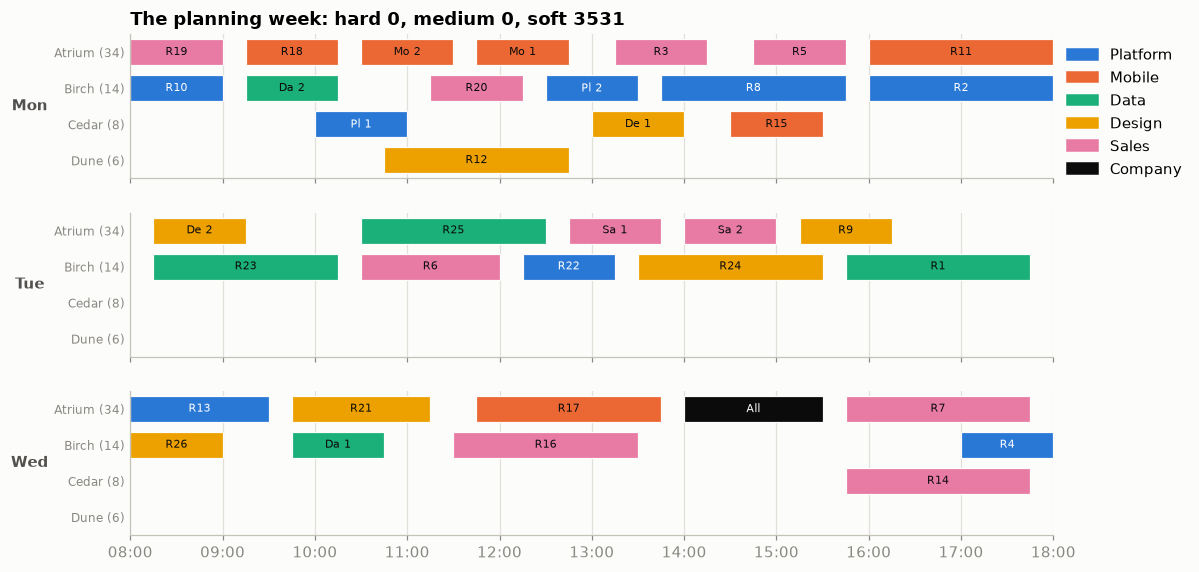

In [4]:
def placements(schedule):
    """(meeting index, room index, start grain position) for every assigned meeting."""
    return [(a.meeting, schedule.room_index_of(a.grain_room), schedule.time_grain_pos_of(a.grain_room))
            for a in schedule.meeting_assignments if a.grain_room >= 0]


LEAD_COLOR = {**{team: COLORS[i] for i, team in enumerate(TEAM_NAMES)}, "Company": "#0b0b0b"}
LABEL_COLOR = {**{team: "#0b0b0b" for team in TEAM_NAMES}, "Platform": "white", "Company": "white"}


def short(topic):
    return topic.replace("Review ", "R").replace(" sync ", " ").replace("All hands", "All")


def draw_calendar(schedule, title, day_count=3, outline=()):
    rooms = schedule.rooms
    fig, axes = plt.subplots(day_count, 1, figsize=(11, 1.5 * day_count + 0.8), sharex=True)
    axes = np.atleast_1d(axes)
    for ax in axes:
        ax.set_ylim(len(rooms) - 0.5, -0.5)
        ax.set_yticks(range(len(rooms)), [f"{r.name} ({r.capacity})" for r in rooms], fontsize=8)
        ax.tick_params(axis="y", length=0)
        ax.grid(True, axis="x")
    for meeting, room, position in placements(schedule):
        day, grain = position // GRAINS_PER_DAY, position % GRAINS_PER_DAY
        duration = schedule.meetings[meeting].duration_in_grains
        topic, *_, lead = MEETINGS[meeting]
        ax = axes[day]
        ax.barh(room, duration / 4, left=8 + grain / 4, height=0.72, color=LEAD_COLOR[lead],
                edgecolor="#0b0b0b" if meeting in outline else "#fcfcfb", linewidth=2 if meeting in outline else 0.8,
                zorder=3 if meeting in outline else 2)
        ax.text(8 + (grain + duration / 2) / 4, room, short(topic), ha="center", va="center", fontsize=7,
                color=LABEL_COLOR[lead], zorder=4)
    for ax, name in zip(axes, DAY_NAMES):
        ax.set_ylabel(name, rotation=0, labelpad=16, va="center", fontweight="bold", color=INK)
    axes[0].set_title(title)
    axes[-1].set_xlim(8, 18)
    axes[-1].set_xticks(range(8, 19), [f"{hour:02d}:00" for hour in range(8, 19)])
    handles = [Patch(color=LEAD_COLOR[name], label=name) for name in LEAD_COLOR]
    axes[0].legend(handles=handles, loc="upper left", bbox_to_anchor=(1, 1))
    fig.tight_layout()
    plt.show()


draw_calendar(week, f"The planning week: hard {week.score.hard}, medium {report(week)['medium']}, soft {report(week)['soft']}")

### The personal calendars

A room calendar hides the real difficulty, which is people. Here each row is a person and each column a
15-minute grain. Dark cells are meetings a person must attend and light cells meetings they would
like to attend. Red marks a grain where someone is listed for two meetings at once.

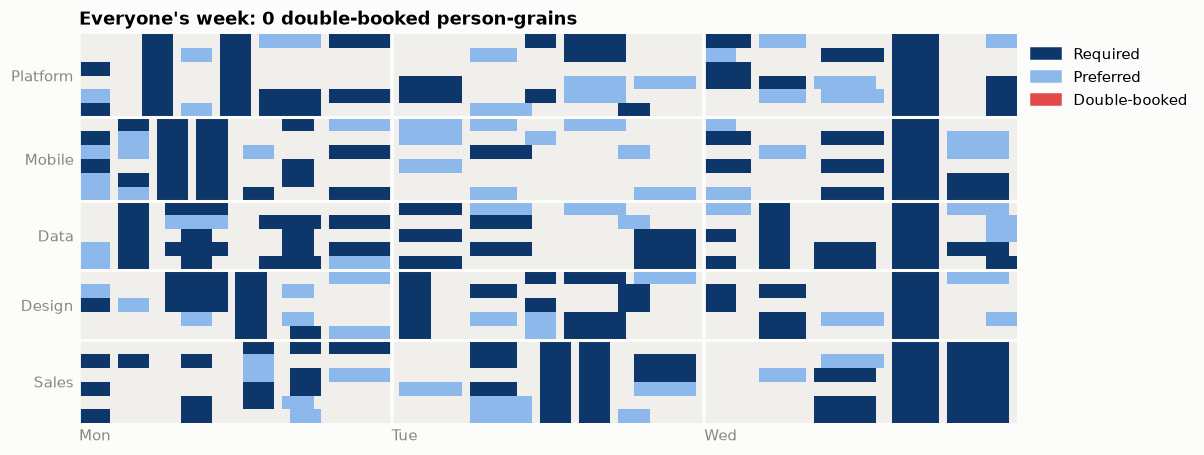

In [5]:
def person_grid(schedule):
    """0 free, 1 preferred, 2 required, 3 double-booked, per person and time grain position."""
    grid = np.zeros((len(schedule.people), schedule.time_grain_count()), dtype=int)
    booked = np.zeros_like(grid)
    for meeting, _, position in placements(schedule):
        m = schedule.meetings[meeting]
        span = range(position, min(position + m.duration_in_grains, schedule.time_grain_count()))
        for person in m.required_attendees:
            grid[person, span] = 2
            booked[person, span] += 1
        for person in m.preferred_attendees:
            grid[person, span] = np.maximum(grid[person, span], 1)
            booked[person, span] += 1
    grid[booked > 1] = 3
    return grid


def draw_people(schedule, title):
    grid = person_grid(schedule)
    fig, ax = plt.subplots(figsize=(11, 4.6))
    ax.imshow(grid, aspect="auto", interpolation="nearest",
              cmap=ListedColormap(["#f0efec", "#8db8ec", "#0d366b", COLORS[7]]), vmin=0, vmax=3)
    ticks = range(0, grid.shape[1], GRAINS_PER_DAY)
    ax.set_xticks([t - 0.5 for t in ticks], [DAY_NAMES[t // GRAINS_PER_DAY] for t in ticks], ha="left")
    for t in ticks:
        ax.axvline(t - 0.5, color="#fcfcfb", linewidth=2.5)
    starts = np.cumsum([0, *TEAMS.values()])[:-1]
    ax.set_yticks(starts + np.array(list(TEAMS.values())) / 2 - 0.5, TEAM_NAMES)
    for start in starts[1:]:
        ax.axhline(start - 0.5, color="#fcfcfb", linewidth=2)
    ax.tick_params(length=0)
    for side in ("left", "bottom"):
        ax.spines[side].set_visible(False)
    handles = [Patch(color="#0d366b", label="Required"), Patch(color="#8db8ec", label="Preferred"),
               Patch(color=COLORS[7], label="Double-booked")]
    ax.legend(handles=handles, loc="upper left", bbox_to_anchor=(1, 1))
    ax.set_title(title)
    plt.show()


grid = person_grid(week)
draw_people(week, f"Everyone's week: {(grid == 3).sum()} double-booked person-grains")

## 3. Check the result yourself

The decision is one integer per meeting. This decodes each one and recomputes all twelve rules with no
solver code, then rebuilds the score from them.

In [6]:
def check_schedule(schedule):
    grains = schedule.time_grains
    grain_by_index = {g.grain_index: g for g in grains}
    capacity = [room.capacity for room in schedule.rooms]
    entries = []
    for meeting, room, position in placements(schedule):
        m = schedule.meetings[meeting]
        start = grains[position].grain_index
        entries.append((m, room, start, start + m.duration_in_grains - 1))

    c = dict.fromkeys(("room", "required", "seats", "day", "overtime", "mixed", "preferred", "adjacent",
                       "overlap", "stability"), 0)
    for m, room, start, last in entries:
        c["seats"] += max(0, m.required_capacity() - capacity[room])
        if last not in grain_by_index:
            c["overtime"] += last
        elif grain_by_index[last].day_of_year != grain_by_index[start].day_of_year:
            c["day"] += 1

    for (a, room_a, start_a, last_a), (b, room_b, start_b, last_b) in combinations(entries, 2):
        overlap = max(0, min(last_a, last_b) - max(start_a, start_b) + 1)
        req_a, req_b = set(a.required_attendees), set(b.required_attendees)
        pref_a, pref_b = set(a.preferred_attendees), set(b.preferred_attendees)
        c["overlap"] += overlap
        c["room"] += overlap if room_a == room_b else 0
        c["required"] += overlap * len(req_a & req_b)
        c["mixed"] += overlap * (len(req_a & pref_b) + len(pref_a & req_b))
        c["preferred"] += overlap * len(pref_a & pref_b)
        c["adjacent"] += last_a + 1 == start_b or last_b + 1 == start_a
        first_last, second_start = (last_a, start_b) if start_a < start_b else (last_b, start_a)
        if room_a != room_b and start_a != start_b and second_start - first_last - 1 <= 2:
            c["stability"] += len((req_a | pref_a) & (req_b | pref_b))

    latest = sum(last for *_, last in entries)
    larger = sum(max(0, other - capacity[room]) for _, room, *_ in entries for other in capacity)
    hard = c["room"] + c["required"] + c["seats"] + c["day"] + c["overtime"]
    medium = c["mixed"] + c["preferred"]
    soft = latest + larger + 100 * c["adjacent"] + 10 * c["overlap"] + c["stability"]
    return c, hard, medium, soft


counts, hard, medium, soft = check_schedule(week)
print("recomputed:", counts)
print(f"recomputed score: hard {-hard}, soft {-(medium * ms.MEDIUM_SCALE + soft)}")
print(f"solver score    : hard {week.score.hard}, soft {week.score.soft}")

recomputed: {'room': 0, 'required': 0, 'seats': 0, 'day': 0, 'overtime': 0, 'mixed': 0, 'preferred': 0, 'adjacent': 0, 'overlap': 107, 'stability': 33}
recomputed score: hard 0, soft -3531.0
solver score    : hard 0, soft -3531.0


## 4. Change the rules, not the solver

`list_constraints()` shows the twelve rules, and `constraints=` takes the list you want. Only listed
constraints are scored.

`room_stability` counts each attendee shared by two meetings in different rooms when the later one starts
at most two grains after the earlier one ends, overlaps included. It has weight 1, so it barely competes
with the rest of the soft level: one back-to-back pair of meetings costs 100. Suppose people complain
about the walking. Raising the weight to 100 makes one room change cost as much as one back-to-back pair,
and the two rules now trade against each other.

`weight` scales a rule, `hard` moves it between levels, and `exponent=2` makes large violations much
costlier than small ones. Medium rules should not be given `hard=False`, which folds them into soft.

['avoid_overtime', 'required_room_capacity', 'start_and_end_on_same_day', 'do_meetings_as_soon_as_possible', 'assign_larger_rooms_first', 'room_conflict', 'required_attendance_conflict', 'required_and_preferred_attendance_conflict', 'preferred_attendance_conflict', 'one_break_between_consecutive_meetings', 'overlapping_meetings', 'room_stability']


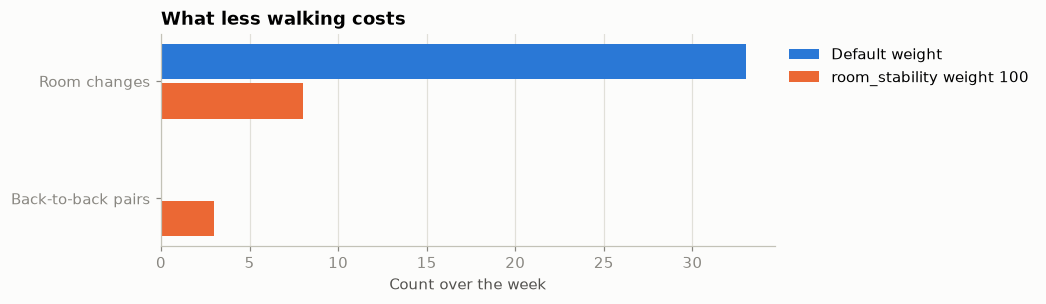

default  : {'hard': 0, 'medium': 0, 'soft': 3531, 'room changes': 33, 'back-to-back pairs': 0, 'overlapping grains': 107}
weight 100: {'hard': 0, 'medium': 0, 'soft': 4067, 'room changes': 8, 'back-to-back pairs': 3, 'overlapping grains': 111}


In [7]:
print(ms.list_constraints())


def with_rule(replacement):
    return rules.get_constraints([replacement if c.name == replacement.name else c for c in rules.get_constraints()])


settled = make_schedule()
ms.solve(settled, constraints=with_rule(rules.RoomStability(weight=100)), **SOLVE)

measures = ["room changes", "back-to-back pairs"]
default_report, settled_report = report(week), report(settled)
y = np.arange(len(measures))
fig, ax = plt.subplots(figsize=(7.2, 2.5))
ax.barh(y - 0.17, [default_report[m] for m in measures], height=0.3, color=COLORS[0], label="Default weight")
ax.barh(y + 0.17, [settled_report[m] for m in measures], height=0.3, color=COLORS[1], label="room_stability weight 100")
ax.set_yticks(y, [m.capitalize() for m in measures])
ax.invert_yaxis()
ax.set(title="What less walking costs", xlabel="Count over the week")
ax.grid(True, axis="x")
ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.show()

print("default  :", default_report)
print("weight 100:", settled_report)

With a changed weight, `score.soft` follows the new weights, so compare counts rather than scores. The
solver runs for a fixed time, so these numbers are the best found in that time rather than proven optima.

## 5. Rooms or people?

Which is the bottleneck: not enough rooms, or not enough time for people to meet? The experiment takes
away rooms and takes away time, and compares what breaks. Medium counts overlaps that cost a preferred
attendee a meeting.

Full week               {'hard': 0, 'medium': 0, 'soft': 3531, 'room changes': 33, 'back-to-back pairs': 0, 'overlapping grains': 107}
Without Birch           {'hard': 0, 'medium': 0, 'soft': 3806, 'room changes': 24, 'back-to-back pairs': 1, 'overlapping grains': 109}
Atrium and Birch only   {'hard': 0, 'medium': 0, 'soft': 4719, 'room changes': 23, 'back-to-back pairs': 13, 'overlapping grains': 87}
Days end at 16:00       {'hard': 0, 'medium': 9, 'soft': 6502, 'room changes': 58, 'back-to-back pairs': 22, 'overlapping grains': 142}
Two days                {'hard': 0, 'medium': 50, 'soft': 9622, 'room changes': 94, 'back-to-back pairs': 56, 'overlapping grains': 183}


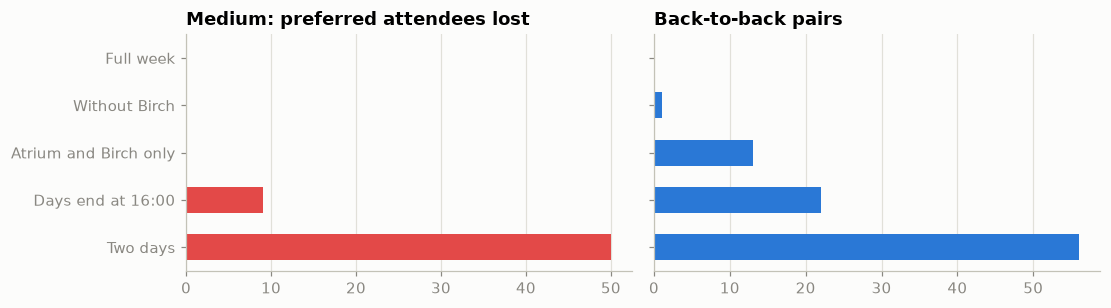

In [8]:
VARIANTS = {
    "Full week": {},
    "Without Birch": {"rooms": [ROOMS[0], ROOMS[2], ROOMS[3]]},
    "Atrium and Birch only": {"rooms": ROOMS[:2]},
    "Days end at 16:00": {"grains_per_day": 32},
    "Two days": {"days": 2},
}
rows = {}
for label, options in VARIANTS.items():
    schedule = make_schedule(**options)
    ms.solve(schedule, time_limit_seconds=2.0, random_seed=42)
    rows[label] = report(schedule)
    print(f"{label:23s} {rows[label]}")

labels = list(rows)
fig, axes = plt.subplots(1, 2, figsize=(10.2, 2.9), sharey=True)
for ax, measure, color, title in ((axes[0], "medium", COLORS[7], "Medium: preferred attendees lost"),
                                  (axes[1], "back-to-back pairs", COLORS[0], "Back-to-back pairs")):
    ax.barh(labels, [rows[label][measure] for label in labels], height=0.55, color=color)
    ax.set_title(title)
    ax.xaxis.get_major_locator().set_params(integer=True)
    ax.grid(True, axis="x")
axes[0].invert_yaxis()
fig.tight_layout()
plt.show()

If taking rooms away changes little and taking time away changes a lot, the limit is people's
calendars. Booking another room would not help, and fewer required attendees might.

## 6. Keep searching from an earlier result

The pydantic models in `optimaru.meeting_scheduling.models` mirror the problem for JSON. `ms.solve`
accepts a model and returns one, and `ms.with_initial_solution` turns an answer into the start of the
next search.

Change `random_seed` between rounds. The same start with the same seed repeats the same search: a round
that finds nothing leaves the next round with the identical input, and from then on nothing changes.
A step limit makes each round repeatable, so the difference between the lines comes from the seeds. The
dotted line is the best of several fresh solves. The two lines can cross, because a few rounds of either
kind are mostly luck. What a new seed buys is a search that does not stop for good. The chart starts at
the first round both lines have no medium conflicts, since the climb before that would hide this.

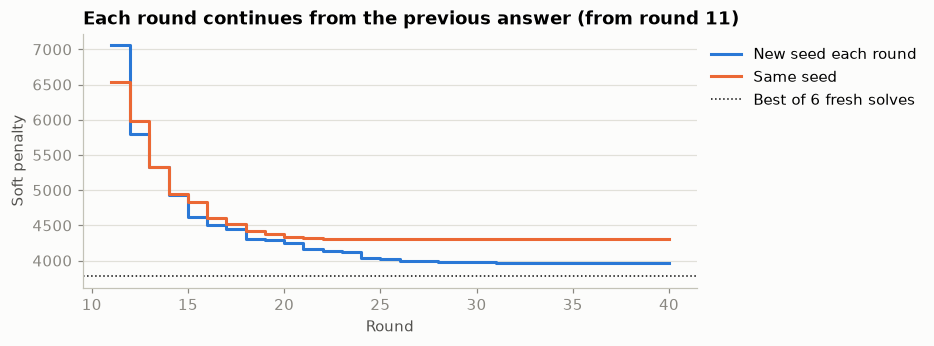

same seed: 15 of 39 rounds repeat the previous score, ends at (0, -4302.0)
new seed : 9 of 39 rounds repeat the previous score, ends at (0, -3969.0)
6 fresh solves: -3780.0 to -4403.0


In [9]:
def run_rounds(rounds, new_seed, steps=5_000):
    problem = MeetingScheduleModel.from_core(make_schedule())
    solution, history = None, []
    for round_number in range(rounds):
        config = ms.SolverConfig()
        config.step_count_limit = steps
        start = problem if solution is None else ms.with_initial_solution(problem, solution)
        solution = ms.solve(start, config=config, time_limit_seconds=30.0,
                            random_seed=1 + round_number if new_seed else 1)
        history.append((solution.score_hard, solution.score_soft))
    return history


ROUNDS = 40
same_seed, new_seed = run_rounds(ROUNDS, False), run_rounds(ROUNDS, True)
fresh_scores = [ms.solve(make_schedule(), time_limit_seconds=0.5, random_seed=100 + i).score.soft for i in range(6)]

clean = max(next(i for i, score in enumerate(history) if score[0] == 0 and -score[1] < ms.MEDIUM_SCALE)
            for history in (same_seed, new_seed))
rounds = range(clean + 1, ROUNDS + 1)
fig, ax = plt.subplots(figsize=(7.2, 3))
for history, color, label in ((new_seed, COLORS[0], "New seed each round"), (same_seed, COLORS[1], "Same seed")):
    ax.plot(rounds, [-history[i - 1][1] for i in rounds], color=color, linewidth=2, drawstyle="steps-post", label=label)
ax.axhline(-max(fresh_scores), color="#0b0b0b", linewidth=1, linestyle=":", label="Best of 6 fresh solves")
ax.set(title=f"Each round continues from the previous answer (from round {clean + 1})", xlabel="Round",
       ylabel="Soft penalty")
ax.grid(True, axis="y")
ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.show()

for label, history in (("same seed", same_seed), ("new seed ", new_seed)):
    repeats = sum(a == b for a, b in zip(history, history[1:]))
    print(f"{label}: {repeats} of {ROUNDS - 1} rounds repeat the previous score, ends at {history[-1]}")
print(f"6 fresh solves: {max(fresh_scores)} to {min(fresh_scores)}")

## 7. The all-hands moves

The first day has happened, and the chief executive can only do Tuesday 14:00 for the all-hands. A
pinned assignment keeps its value. Pinned assignments count in the score here, and `grain_room` encodes
the (grain, room) pair directly.

People have already seen the calendar, so the goal is to keep it. A warm start sets where the search
begins and promises nothing about where it ends, and this use case has no cost for changing a meeting.
The way to ask for stability here is to pin it: free only the meetings that clash with the new slot.

In [10]:
problem = MeetingScheduleModel.from_core(make_schedule())
solved = ms.solve(problem, time_limit_seconds=3.0, random_seed=1)

room_count = len(problem.rooms)
NEW_SLOT = GRAINS_PER_DAY + 24  # Tuesday 14:00
was = {a.id: a.grain_room for a in solved.meeting_assignments}
hands_id = solved.meeting_assignments[ALL_HANDS].id
hands_length = problem.meetings[ALL_HANDS].duration_in_grains


def clashes(assignment):
    start = was[assignment.id] // room_count
    length = problem.meetings[assignment.meeting].duration_in_grains
    return start < NEW_SLOT + hands_length and start + length > NEW_SLOT


def replan(keep_clear_of_slot):
    """Pin the all-hands to the new slot and Monday in place, plus everything else if asked."""
    changed = problem.model_copy(deep=True)
    for assignment in changed.meeting_assignments:
        if assignment.id == hands_id:
            assignment.grain_room, assignment.pinned = NEW_SLOT * room_count, True
        elif was[assignment.id] // room_count < GRAINS_PER_DAY or (keep_clear_of_slot and not clashes(assignment)):
            assignment.grain_room, assignment.pinned = was[assignment.id], True
    return changed


plans = {
    "Fresh solve": ms.solve(replan(False), time_limit_seconds=1.0, random_seed=2),
    "Warm start": ms.solve(ms.with_initial_solution(replan(False), solved), time_limit_seconds=1.0, random_seed=2),
    "Pin all but the clashes": ms.solve(replan(True), time_limit_seconds=1.0, random_seed=2),
}
free = sum(not a.pinned for a in replan(False).meeting_assignments)
for label, plan in plans.items():
    moved = sum(a.grain_room != was[a.id] for a in plan.meeting_assignments if a.id != hands_id)
    b = ms.compute_breakdown(plan.to_core())
    print(f"{label:24s} hard {plan.score_hard}, medium {b.medium_total()}, soft {b.soft_total()}, {moved} of {free} free meetings moved")

Fresh solve              hard 0, medium 0, soft 3607, 20 of 21 free meetings moved
Warm start               hard 0, medium 0, soft 3651, 20 of 21 free meetings moved
Pin all but the clashes  hard 0, medium 0, soft 4145, 4 of 21 free meetings moved


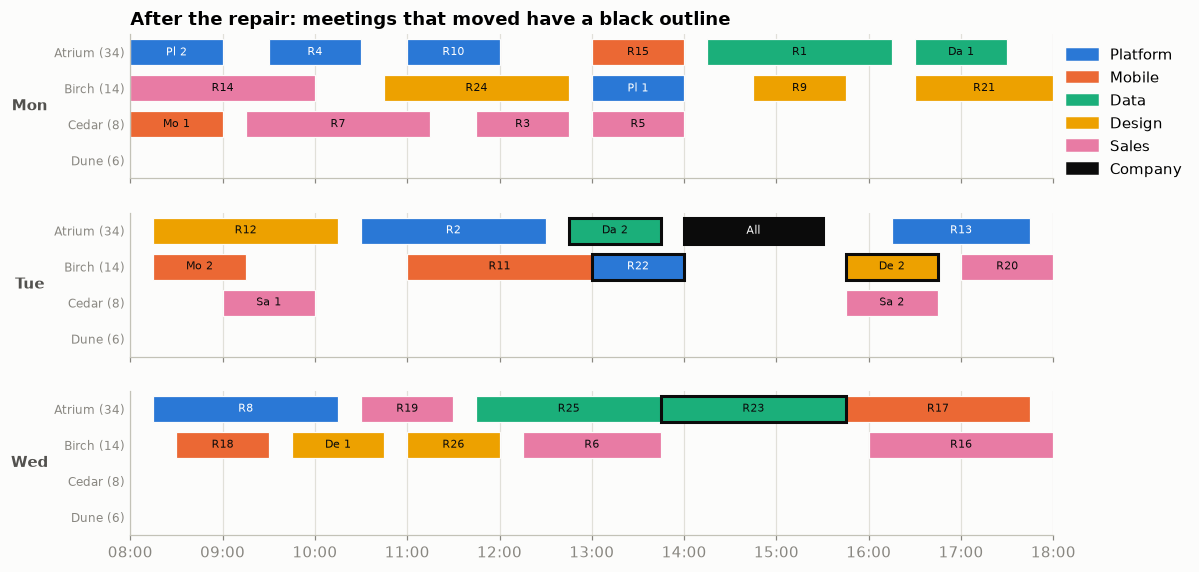

In [11]:
repaired = plans["Pin all but the clashes"].to_core()
ms.calculate_score(repaired)
moved_meetings = [a.meeting for a in plans["Pin all but the clashes"].meeting_assignments if a.grain_room != was[a.id]]
draw_calendar(repaired, "After the repair: meetings that moved have a black outline", outline=moved_meetings)

Pinning trades quality for stability, so read the medium and soft counts above next to the number of
changes.

## Next steps

- `use-cases/meeting-scheduling/README.md` covers the solver configuration and how to add your own moves and
  constraints in C++.
- For rostering people onto shifts rather than meetings into rooms, see `employee-scheduling.ipynb`.